#### TheLook eCommerce dataset

This is a synthetic dataset created by Looker team. Google rewrites this public dataset every day, therefore, we'll run our analysis on the snapshot taken on a duckdb dataset. The only exception is Appendix A, which compares the snapshot with the live tables.

We need to check keys, relationships, lifecycle rules, timestamps alignments we need for batch simulator.

### 1. Setup

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [2]:
load_dotenv()
DUCKDB_PATH = os.getenv("DUCKDB_PATH")
if not DUCKDB_PATH or not Path(DUCKDB_PATH).exists():
    raise FileNotFoundError(f"DUCKDB_PATH is missing or file not exist: {DUCKDB_PATH!r}. Check .env file.")

# Appendix A compares the snapshot with the live tables and needs GCP credentials.
CHECK_LIVE_SOURCE = False
TABLES = ["distribution_centers", "events", "inventory_items", "order_items", "orders", "products", "users"]

con = duckdb.connect(DUCKDB_PATH, read_only=True)
con.sql("SET TimeZone='UTC'")  # day boundaries and displayed timestamps are UTC, not the machine's timezone

In [ ]:
def q(sql: str) -> pd.DataFrame:
    """Run a query and return a DataFrame"""
    return con.execute(sql).df()
q("SELECT current_setting('TimeZone') AS session_timezone")

,session_timezone
0,UTC


### 2. Snapshot Overview


Is the snapshot one consistent version of the source, and how far do its dates run?

*`snapshot.py` writes `_snapshot_manifest` last, so its presence means the copy finished. It records each table's row count and the source's last-modified time.

In [4]:
manifest = q("""
    SELECT table_name, row_count, source_modified_at_utc, snapshot_taken_at_utc
    FROM _snapshot_manifest
    ORDER BY table_name
""")
manifest

,table_name,row_count,source_modified_at_utc,snapshot_taken_at_utc
0,distribution_centers,10,2026-10-15 04:02:20.620,2026-10-15 14:23:20.689588
1,events,2421494,2026-10-15 04:01:59.415,2026-10-15 14:23:20.689588
2,inventory_items,488459,2026-10-15 04:01:55.340,2026-10-15 14:23:20.689588
3,order_items,181081,2026-10-15 04:01:49.575,2026-10-15 14:23:20.689588
4,orders,125004,2026-10-15 04:01:54.719,2026-10-15 14:23:20.689588
5,products,29120,2026-10-15 04:01:47.555,2026-10-15 14:23:20.689588
6,users,100000,2026-10-15 04:02:11.990,2026-10-15 14:23:20.689588


All seven tables were last modified within 33 seconds of each other (04:01:47 to 04:02:20 UTC on 2026-10-15) so it holds one consistent version of the source. 

- Rows: events 2421494; inventory_items 488459; order_items 181081; orders 125004; products 29120; users 100000; distribution_centers 10.

In [5]:
# Min and max of every timestamp column in every table
ts_cols = q("""
    SELECT table_name, column_name
    FROM information_schema.columns
    WHERE table_schema = 'main'
      AND data_type LIKE 'TIMESTAMP%'
      AND table_name <> '_snapshot_manifest'
    ORDER BY table_name, ordinal_position
""")
time_ranges = q(" UNION ALL ".join(
    f"""SELECT '{t}' AS table_name, '{c}' AS column_name, min("{c}") AS min_value, max("{c}") AS max_value FROM "{t}" """
    for t, c in ts_cols.itertuples(index=False)
))
time_ranges

,table_name,column_name,min_value,max_value
0,events,created_at,2019-01-02 00:11:00+00:00,2026-10-18 23:33:58+00:00
1,inventory_items,created_at,2018-12-26 17:31:31+00:00,2026-10-18 21:46:50.235486+00:00
2,inventory_items,sold_at,2019-01-19 07:23:29+00:00,2026-10-18 23:33:58+00:00
3,order_items,created_at,2019-01-19 07:23:29+00:00,2026-10-18 23:33:58+00:00
4,order_items,shipped_at,2019-02-08 12:28:22+00:00,2026-10-17 23:07:28.681034+00:00
5,order_items,delivered_at,2019-02-10 19:47:52+00:00,2026-10-22 14:39:41+00:00
6,order_items,returned_at,2019-02-15 18:59:33+00:00,2026-10-24 19:39:24.098679+00:00
7,orders,created_at,2019-01-19 10:08:54+00:00,2026-10-15 00:41:14+00:00
8,orders,returned_at,2019-02-15 18:59:33+00:00,2026-10-24 19:39:24.098679+00:00
9,orders,shipped_at,2019-02-08 12:28:22+00:00,2026-10-17 23:07:28.681034+00:00


We took our snapshot on 15 Oct 2026 and order creation (created_at) is on the same day. However, we can see there are timestamps for shipped, delivered, returned which has not yet happend but present in the dataset since this is a synthetically generated dataset.

### 3. Orders

In [6]:
orders = q("SELECT * FROM orders")
print(orders.info())
orders.sample(5, random_state=1)

<class 'pandas.DataFrame'>
RangeIndex: 125004 entries, 0 to 125003
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   order_id      125004 non-null  int64              
 1   user_id       125004 non-null  int64              
 2   status        125004 non-null  str                
 3   gender        125004 non-null  str                
 4   created_at    125004 non-null  datetime64[us, UTC]
 5   returned_at   12418 non-null   datetime64[us, UTC]
 6   shipped_at    81366 non-null   datetime64[us, UTC]
 7   delivered_at  43688 non-null   datetime64[us, UTC]
 8   num_of_item   125004 non-null  int64              
dtypes: datetime64[us, UTC](4), int64(3), str(2)
memory usage: 9.7 MB
None


,order_id,user_id,status,gender,created_at,returned_at,shipped_at,delivered_at,num_of_item
90288,27249,21853,Processing,M,2021-07-19 23:58:51+00:00,NaT,NaT,NaT,1
55175,74816,59909,Shipped,F,2025-12-26 22:59:54+00:00,NaT,2025-12-27 03:01:54+00:00,NaT,1
21948,98596,78969,Complete,F,2026-06-13 15:57:26+00:00,NaT,2026-06-15 15:21:26+00:00,2026-06-17 14:37:26+00:00,1
60468,109215,87417,Shipped,F,2026-01-31 19:59:31+00:00,NaT,2026-02-02 15:38:31+00:00,NaT,1
89098,15377,12454,Processing,M,2022-03-09 12:44:25+00:00,NaT,NaT,NaT,1


One row per order.

In [7]:
print("duplicate order_id:", orders["order_id"].duplicated().sum())
print("null user_id:", orders["user_id"].isna().sum())

duplicate order_id: 0
null user_id: 0


In [8]:
status_counts = orders["status"].value_counts().rename_axis("status").reset_index(name="orders")
status_counts["share"] = (status_counts["orders"] / status_counts["orders"].sum()).round(2)
status_counts

,status,orders,share
0,Shipped,37678,0.30
1,Complete,31270,0.25
2,Processing,24819,0.20
3,Cancelled,18819,0.15
4,Returned,12418,0.10


How does `status` relate to the lifecycle timestamps?

In [9]:
status_vs_dates = q("""
    SELECT status,
       count(*) AS orders,
       count(created_at)  AS has_created,
       count(shipped_at) AS has_shipped,
       count(delivered_at) AS has_delivered,
       count(returned_at) AS has_returned
    FROM orders
    GROUP BY status
    ORDER BY CASE 
       status WHEN 'Processing' THEN 1 
       WHEN 'Cancelled' THEN 2 
       WHEN 'Shipped' THEN 3
       WHEN 'Complete' THEN 4 
       WHEN 'Returned' THEN 5 
       ELSE 6 
       END
""")
status_vs_dates

,status,orders,has_created,has_shipped,has_delivered,has_returned
0,Processing,24819,24819,0,0,0
1,Cancelled,18819,18819,0,0,0
2,Shipped,37678,37678,37678,0,0
3,Complete,31270,31270,31270,31270,0
4,Returned,12418,12418,12418,12418,12418


order lifecycle >>> [Processing (or Cancelled) -> Shipped -> Complete -> Returned (if delivered) ]  <br>
Lifecycle timestamp cols >>> `created_at` -> `shipped_at` -> `delivered_at`, `returned_at`. <br>
Cancelled orders carry no date after `created_at`, so the cancellation itself is undated.

Our incremental batch simulator will replay one simulated day at a time, and mask every timestamp later than that day, and derives the status from the timestamps that remain.

In [10]:
# are lifecycle dates always in order, and never present without their predecessor?
date_order_violations = q("""
    SELECT count(*) FILTER (WHERE shipped_at < created_at) AS shipped_before_created,
        count(*) FILTER (WHERE delivered_at < shipped_at) AS delivered_before_shipped,
        count(*) FILTER (WHERE returned_at < delivered_at) AS returned_before_delivered,
        count(*) FILTER (WHERE delivered_at IS NOT NULL AND shipped_at IS NULL) AS delivered_without_shipped,
        count(*) FILTER (WHERE returned_at IS NOT NULL AND delivered_at IS NULL) AS returned_without_delivered
    FROM orders
""")
date_order_violations

,shipped_before_created,delivered_before_shipped,returned_before_delivered,delivered_without_shipped,returned_without_delivered
0,0,0,0,0,0


There are no violations in lifecycle dates.

In [11]:
order_items = q("SELECT * FROM order_items")
print(order_items.info())
order_items.sample(5)

<class 'pandas.DataFrame'>
RangeIndex: 181081 entries, 0 to 181080
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   id                 181081 non-null  int64              
 1   order_id           181081 non-null  int64              
 2   user_id            181081 non-null  int64              
 3   product_id         181081 non-null  int64              
 4   inventory_item_id  181081 non-null  int64              
 5   status             181081 non-null  str                
 6   created_at         181081 non-null  datetime64[us, UTC]
 7   shipped_at         118000 non-null  datetime64[us, UTC]
 8   delivered_at       63257 non-null   datetime64[us, UTC]
 9   returned_at        17986 non-null   datetime64[us, UTC]
 10  sale_price         181081 non-null  float64            
dtypes: datetime64[us, UTC](4), float64(1), int64(5), str(1)
memory usage: 16.6 MB
None


,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
135911,126337,87246,69941,26884,340658,Complete,2026-10-07 02:21:50+00:00,2026-10-06 23:44:26+00:00,2026-10-11 13:53:26+00:00,NaT,69.949997
135381,113931,78670,63001,28074,307276,Returned,2023-07-30 19:02:41+00:00,2023-07-27 07:45:54+00:00,2023-07-29 04:17:54+00:00,2023-07-31 11:08:54+00:00,69.500000
100610,8297,5738,4721,16619,22339,Processing,2025-10-19 06:42:20+00:00,NaT,NaT,NaT,45.000000
156172,116780,80645,64555,24329,314927,Shipped,2026-06-23 06:25:16+00:00,2026-06-24 05:17:19+00:00,NaT,NaT,100.000000
128734,110871,76552,61263,711,299036,Cancelled,2024-04-02 19:29:25+00:00,NaT,NaT,NaT,64.000000


In [12]:
# Does num_of_item agree with the number of item rows?
num_of_item_check = q("""
    WITH items AS (SELECT order_id, count(*) AS n_items FROM order_items GROUP BY order_id)
    SELECT count(*) AS orders,
        count(*) FILTER (WHERE i.order_id IS NULL) AS orders_without_items,
        count(*) FILTER (WHERE i.order_id IS NOT NULL AND i.n_items <> o.num_of_item) AS num_of_item_mismatch
    FROM orders o
    LEFT JOIN items i ON i.order_id = o.order_id
""")
num_of_item_check

,orders,orders_without_items,num_of_item_mismatch
0,125004,0,0


### 4. Order items

In [13]:
order_items = q("SELECT * FROM order_items")
print(order_items.info())
order_items.sample(3, random_state=1)

<class 'pandas.DataFrame'>
RangeIndex: 181081 entries, 0 to 181080
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   id                 181081 non-null  int64              
 1   order_id           181081 non-null  int64              
 2   user_id            181081 non-null  int64              
 3   product_id         181081 non-null  int64              
 4   inventory_item_id  181081 non-null  int64              
 5   status             181081 non-null  str                
 6   created_at         181081 non-null  datetime64[us, UTC]
 7   shipped_at         118000 non-null  datetime64[us, UTC]
 8   delivered_at       63257 non-null   datetime64[us, UTC]
 9   returned_at        17986 non-null   datetime64[us, UTC]
 10  sale_price         181081 non-null  float64            
dtypes: datetime64[us, UTC](4), float64(1), int64(5), str(1)
memory usage: 16.6 MB
None


,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
156455,90968,62865,50419,3195,245519,Complete,2021-12-16 11:37:20+00:00,2021-12-17 22:14:22+00:00,2021-12-20 14:49:22+00:00,NaT,101.989998
96384,35910,24878,19985,23589,96959,Shipped,2024-04-25 18:20:46+00:00,2024-04-28 02:45:49+00:00,NaT,NaT,43.480000
22453,92967,64211,51458,9307,250939,Returned,2021-05-19 17:52:40+00:00,2021-05-16 08:23:32+00:00,2021-05-21 05:21:32+00:00,2021-05-22 17:14:32+00:00,15.000000


One row per line item. It repeats the order's lifecycle columns and has its own `created_at`.

In [14]:
print("duplicate id:", order_items["id"].duplicated().sum())

duplicate id: 0


In [15]:
# does an item and its order agree on status, user and dates?
item_vs_order = q("""
    SELECT count(*) AS joined_rows,
        count(*) FILTER (WHERE oi.status IS DISTINCT FROM o.status) AS status_differs,
        count(*) FILTER (WHERE oi.user_id IS DISTINCT FROM o.user_id) AS user_id_differs,
        count(*) FILTER (WHERE oi.created_at IS DISTINCT FROM o.created_at) AS created_at_differs,
        count(*) FILTER (WHERE oi.shipped_at IS DISTINCT FROM o.shipped_at) AS shipped_at_differs,
        count(*) FILTER (WHERE oi.delivered_at IS DISTINCT FROM o.delivered_at) AS delivered_at_differs,
        count(*) FILTER (WHERE oi.returned_at IS DISTINCT FROM o.returned_at) AS returned_at_differs
    FROM order_items oi
    JOIN orders o ON oi.order_id = o.order_id
""")
item_vs_order

,joined_rows,status_differs,user_id_differs,created_at_differs,shipped_at_differs,delivered_at_differs,returned_at_differs
0,181081,0,0,181076,0,0,0


In [16]:
# how many orders have items with different created_at values
items_per_order = q("""
    SELECT count(*) AS orders_with_items,
        count(*) FILTER (WHERE n_items > 1) AS multi_item_orders,
        count(*) FILTER (WHERE n_created > 1)  AS orders_whose_items_have_different_created_at
    FROM (
        SELECT order_id, count(*) AS n_items, count(DISTINCT created_at) AS n_created
        FROM order_items GROUP BY order_id)
""")
items_per_order

,orders_with_items,multi_item_orders,orders_whose_items_have_different_created_at
0,125004,37433,37433


Status, `shipped_at`, `delivered_at` and `returned_at` are identical on item and order for all items. Only `created_at` differs. Nearly all items have a different value from their order's.

Items should follow their order's lifecycle, so the simulator can derive item rows from the order's timestamps instead of the order_item timestamps.

In [17]:
lag = q("""
SELECT oi.id AS order_item_id,
    oi.order_id,
    oi.created_at AS item_created_at,
    o.created_at  AS order_created_at,
    o.shipped_at  AS order_shipped_at,
    (epoch(oi.created_at) - epoch(o.created_at)) / 3600.0 AS lag_hours
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
""")
lag["lag_hours"].describe()

count    181081.000000
mean         22.931099
std          34.248999
min          -3.951111
25%          -2.166389
50%          -0.459444
75%          46.504444
max          96.419167
Name: lag_hours, dtype: float64

In [18]:
total = len(lag)
lag_summary = pd.Series({
    "all items": total,
    "item created earlier than its order": int((lag["lag_hours"] < 0).sum()),
    "item exactly at its order time": int((lag["lag_hours"] == 0).sum()),
    "item created after its order": int((lag["lag_hours"] > 0).sum()),
    "after the order's shipped_at": int((lag["item_created_at"] > lag["order_shipped_at"]).sum()),
}).to_frame("items")
lag_summary["share"] = (lag_summary["items"] / total).round(2)
lag_summary

,items,share
all items,181081,1.00
item created earlier than its order,102697,0.57
item exactly at its order time,5,0.00
item created after its order,78379,0.43
after the order's shipped_at,35783,0.20


Text(0, 0.5, 'order_items')

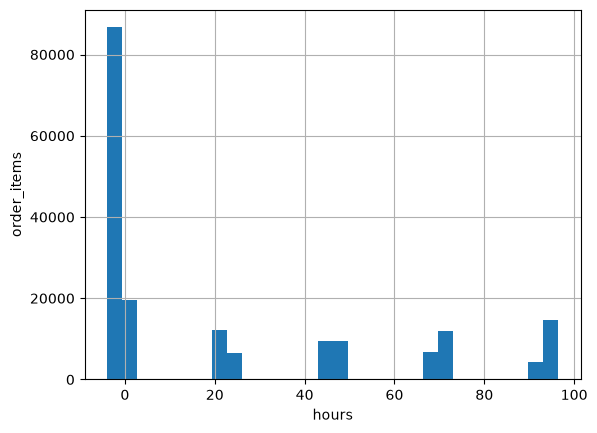

In [19]:
plt.figure()
lag['lag_hours'].hist(bins=30)
plt.xlabel("hours")
plt.ylabel("order_items")

Apparently, the order_items's created_at timestamp are not accurate. Nearly 60% of order items are created before order creation time. The delay is also there for some order_items all the close to 100 hours of lag in total. The lag also appears to be not at random since the bins are separated at regular intervals. Since this is a synthetic dataset, i think this is artifically generated inconsistancy. We'll only use orders created at timestamp.

Order item's `created_at` does not follow the order's. Only 5 items match exactly. 57% are created before their order. The lags are not spread randomly, they cluster near whole days (about 1, 2, 3 and 4 days), which looks generated, not random. 20% of all items are also created after their own order shipped.

Order_item's `created_at` timestamps are unreliable, most likely an artifact of how this synthetic dataset is generated. We'll keep the column but should not use it. `orders.created_at` is the order date everywhere in the marts. The simulator should also delivers an item with its order, on the order's created date.

### 5. Users

In [20]:
users = q("SELECT * FROM users")
print(users.info())
users.sample(3, random_state=1)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   id              100000 non-null  int64              
 1   first_name      100000 non-null  str                
 2   last_name       100000 non-null  str                
 3   email           100000 non-null  str                
 4   age             100000 non-null  int64              
 5   gender          100000 non-null  str                
 6   state           100000 non-null  str                
 7   street_address  100000 non-null  str                
 8   postal_code     100000 non-null  str                
 9   city            100000 non-null  str                
 10  country         100000 non-null  str                
 11  latitude        100000 non-null  float64            
 12  longitude       100000 non-null  float64            
 13  traffic_source  100000 non

,id,first_name,last_name,email,age,gender,state,street_address,postal_code,city,country,latitude,longitude,traffic_source,created_at,user_geom
43660,76585,Lisa,Banks,lisabanks@example.com,44,F,Henan,029 Cameron Brook,466002,Taizhou,China,33.601435,114.650950,Search,2020-06-26 12:05:00+00:00,POINT(114.6509497 33.6014345)
87278,78902,Gina,Bartlett,ginabartlett@example.com,15,F,São Paulo,37769 Caitlin Manor Suite 380,07432-575,Arujá,Brasil,-23.384538,-46.323117,Search,2026-04-16 05:42:00+00:00,POINT(-46.32311742 -23.38453823)
14317,61857,Richard,Alexander,richardalexander@example.org,61,M,Castilla-La Mancha,0518 Wilson Causeway Apt. 614,13005,Ciudad Real,Spain,38.953492,-3.948492,Search,2025-04-13 07:49:00+00:00,POINT(-3.948492026 38.95349206)


In [21]:
print("duplicate id:", users["id"].duplicated().sum())

duplicate id: 0


In [22]:
users_without_orders = q("""
    SELECT 
        COUNT(*) AS users,
        COUNT(*) FILTER (WHERE o.user_id IS NULL) AS users_without_orders
    FROM users u
    LEFT JOIN (SELECT DISTINCT user_id FROM orders) o ON o.user_id = u.id 
""")
users_without_orders["share"]  = (users_without_orders["users_without_orders"] / users_without_orders["users"]).round(2)
users_without_orders

,users,users_without_orders,share
0,100000,19974,0.2


In [23]:
# any users exist before their first order, item and event?
def activity_before_signup(table: str, user_col: str = "user_id", ts_col: str = "created_at") -> pd.DataFrame:
    """Users whose first row in provided table is earlier than their signup."""
    return q(f"""
        SELECT u.id AS user_id,
               u.created_at AS signed_up_at,
               a.first_at,
               (epoch(u.created_at) - epoch(a.first_at)) / 3600.0 AS hours_before_signup
        FROM users u
        JOIN (SELECT {user_col} AS user_id, min({ts_col}) AS first_at
              FROM {table}
              WHERE {user_col} IS NOT NULL
              GROUP BY 1) a ON a.user_id = u.id
        WHERE a.first_at < u.created_at
    """)

before_signup = {t: activity_before_signup(t) for t in ["orders", "order_items", "events"]}
n_users = len(users)
before_signup_summary = pd.DataFrame({
    "users_affected": {t: len(d) for t, d in before_signup.items()},
    "max_hours_before_signup": {t: round(d["hours_before_signup"].max(), 2) for t, d in before_signup.items()},
})
before_signup_summary["share_of_users"] = (before_signup_summary["users_affected"] / n_users).round(4)
before_signup_summary

,users_affected,max_hours_before_signup,share_of_users
orders,0,NaN,0.0000
order_items,141,3.73,0.0014
events,190,3.85,0.0019


A user's first activity should not happen before their signup (`users.created_at`). 
For users where their order_items timestamp predates their signup timestamp will be resolved since we decided earlier to use order created_at timestamps instead of order_item created_at timestamps. And no user's first order precedes their signup

As for events, we'll leave that be since they could be the reason for first touch attribution.

In [24]:
#  which users have events before signup, and what do those events look like?
first_events = q("""
    SELECT u.id AS user_id,
        u.created_at AS signed_up_at,
        f.first_at,
        f.first_event_type,
        f.first_traffic_source,
        (epoch(u.created_at) - epoch(f.first_at)) / 3600.0 AS hours_before_signup
    FROM users u
    JOIN (
        SELECT user_id,
            min(created_at)                    AS first_at,
            arg_min(event_type, created_at)    AS first_event_type,
            arg_min(traffic_source, created_at) AS first_traffic_source
        FROM events
        WHERE user_id IS NOT NULL
        GROUP BY user_id
    ) f ON f.user_id = u.id
""")
pre_signup = first_events[first_events["hours_before_signup"] > 0]
print("users with a first event before signup:", len(pre_signup))
pre_signup["hours_before_signup"].describe()

users with a first event before signup: 190


count    190.000000
mean       1.552401
std        0.997787
min        0.001667
25%        0.710625
50%        1.411667
75%        2.264306
max        3.848333
Name: hours_before_signup, dtype: float64

In [25]:
# The traffic-source mix only means something against a baseline: every user's first event.
traffic_mix = pd.concat({
    "users with events before signup": pre_signup["first_traffic_source"].value_counts(normalize=True),
    "all users' first event": first_events["first_traffic_source"].value_counts(normalize=True),
}, axis=1).round(3)
traffic_mix

,users with events before signup,all users' first event
first_traffic_source,,
Email,0.479,0.447
Adwords,0.237,0.302
YouTube,0.142,0.100
Facebook,0.084,0.099
Organic,0.058,0.052


In [26]:
first_type_mix = pd.concat({
    "users with events before signup": pre_signup["first_event_type"].value_counts(normalize=True),
    "all users' first event": first_events["first_event_type"].value_counts(normalize=True),
}, axis=1).round(3)
first_type_mix

,users with events before signup,all users' first event
first_event_type,,
home,0.626,0.699
department,0.374,0.301
product,NaN,0.001


190 users have a first event before signup. A working hypothesis that the data cannot test is that these are visits made before signup that were later attached to the new user identity stitching, with the traffic source crediting the channel that brought the user in. There is no signup event in `events`, and a user may sign up and leave, so it cannot be confirmed.

However, the cause does not change anything. We'll keep the rows, flag them in intermediate, and run the `events.user_id` relationship test at `warn`. In the simulator an event can briefly arrive before its user; that is accepted as realistic late-arriving data.

### 6. Events

In [27]:
con.sql("DESCRIBE events").df()[["column_name", "column_type"]]

,column_name,column_type
0,id,BIGINT
1,user_id,BIGINT
2,sequence_number,BIGINT
3,session_id,VARCHAR
4,created_at,TIMESTAMP WITH TIME ZONE
5,ip_address,VARCHAR
6,city,VARCHAR
7,state,VARCHAR
8,postal_code,VARCHAR
9,browser,VARCHAR


In [28]:
q("SELECT * FROM events USING SAMPLE 5 ROWS (reservoir, 1)")

,id,user_id,sequence_number,session_id,created_at,ip_address,city,state,postal_code,browser,traffic_source,uri,event_type
0,1268447,97794,12,e24eb3d6-a9df-46d3-ac7b-039debbab211,2026-10-07 14:33:08+00:00,175.32.164.254,Beijing,Hebei,54002,Firefox,YouTube,/cart,cart
1,959607,74127,9,13de9312-1b50-40c2-8729-64169fc624f4,2026-08-30 04:26:08+00:00,73.193.110.195,Zhongshan,Zhejiang,310004,Chrome,Email,/cart,cart
2,1001123,77289,6,7e8fa728-fb63-444a-8642-8231038ae3ca,2026-08-06 03:24:25+00:00,100.13.93.151,Alcañiz,Aragón,44600,Safari,Facebook,/cart,cart
3,2013711,<NA>,3,f17c904c-6374-43d7-863b-2f90a8c43a3d,2025-12-23 01:43:00+00:00,16.54.157.98,Ananindeua,Pará,67100,Chrome,Email,/cart,cart
4,255116,19869,1,573fe282-97af-4efc-99c5-76fab2ec9d14,2026-04-12 17:55:22+00:00,172.95.153.220,Glenview,Illinois,60025,Firefox,Organic,/department/women/category/tops&tees/brand/all...,department


One row per page view or action. Browsing before login has `user_id` empty.

In [29]:
event_types = q("""
    SELECT event_type,
        count(*) events,
        count(*) FILTER (WHERE user_id IS NULL) AS anonymous_events
    FROM events
    GROUP BY event_type
    ORDER BY events DESC
""")
event_types

,event_type,events,anonymous_events
0,product,842871,500000
1,department,592655,249784
2,cart,592571,249700
3,purchase,181081,0
4,cancel,124745,124745
5,home,87571,0


In [30]:
# print(orders.shape)
print(order_items.shape)

(181081, 11)


No anonymous purchase events  and total purchase events count is same as total order_items.

In [31]:
order_items['status'].value_counts()

status
Shipped       54743
Complete      45271
Processing    35798
Cancelled     27283
Returned      17986
Name: count, dtype: int64

In [32]:
# Do cancel and purchase events describe cancelled orders and purchased items?
events_vs_orders = q("""
    SELECT
        (SELECT count(*) FROM events WHERE event_type = 'cancel') AS cancel_events,
        (SELECT count(*) FROM orders WHERE status = 'Cancelled') AS cancelled_orders,
        (SELECT count(*) FROM events WHERE event_type = 'purchase') AS purchase_events,
        (SELECT count(*) FROM order_items) AS order_item_rows
""")
events_vs_orders["cancel_events_per_cancelled_order"] = (
    events_vs_orders["cancel_events"] / events_vs_orders["cancelled_orders"]).round(2)
events_vs_orders

,cancel_events,cancelled_orders,purchase_events,order_item_rows,cancel_events_per_cancelled_order
0,124745,18819,181081,181081,6.63


In [33]:
# do purchase events share a user and a timestamp with an order item?
purchase_vs_items = q("""
    WITH items AS (SELECT DISTINCT user_id, created_at FROM order_items)
    SELECT count(*) AS purchase_events,
           count(i.user_id) AS with_item_at_same_user_and_time
    FROM events e
    LEFT JOIN items i ON i.user_id = e.user_id AND i.created_at = e.created_at
    WHERE e.event_type = 'purchase'
""")
purchase_vs_items

,purchase_events,with_item_at_same_user_and_time
0,181081,93998


`events` has no `order_id`, so events cannot be tied to orders by key. There are 124,745 `cancel` events against 18,819 Cancelled orders (nearly 7 to 1), so `cancel` events are not order cancellations. What they mean is unknown. `purchase` events (181,081) equal the number of order items, but the equal count is not a link. Purchase events sharing a user and timestamp with an item: 93998

Events do not drive any other table. They are insert-only and arrive on their own `created_at`.

### 7. Inventory, products and distribution centers

In [34]:
con.sql("DESCRIBE inventory_items").df()[["column_name", "column_type"]]

,column_name,column_type
0,id,BIGINT
1,product_id,BIGINT
2,created_at,TIMESTAMP WITH TIME ZONE
3,sold_at,TIMESTAMP WITH TIME ZONE
4,cost,DOUBLE
5,product_category,VARCHAR
6,product_name,VARCHAR
7,product_brand,VARCHAR
8,product_retail_price,DOUBLE
9,product_department,VARCHAR


In [35]:
q("SELECT * FROM inventory_items USING SAMPLE 5 ROWS (reservoir, 1)")

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,398650,28971,2023-01-19 07:40:00+00:00,NaT,114.996000,Accessories,Costa Del Mar - Blackfin - Camo Frame-580 Gree...,Costa Del Mar,259.000000,Men,1AA4D17F2DCDAE2F4CED909341741792,3
1,403174,28626,2025-05-05 08:07:02+00:00,2025-05-09 04:05:02+00:00,29.661449,Accessories,Klondike Sterling Russian Rabbit Fur Trooper H...,Klondike Sterling,79.949997,Men,A352147F3AAD581BED027339AC1D5DD9,1
2,274878,29058,2022-11-28 09:37:00+00:00,NaT,26.000000,Accessories,Oakley Flak Jacket Standard Replacement Lens R...,Oakley,65.000000,Men,50C0825021514D9E67849B768C681EC1,8
3,368868,28492,2020-08-22 14:52:00+00:00,NaT,24.384000,Accessories,Pendleton Men's Outback Hat,Pendleton,64.000000,Men,297E6E1F21723046A8C1115EC1A8B8A7,9
4,100830,14227,2020-06-26 16:54:00+00:00,NaT,68.045000,Accessories,Ray-Ban Aviator 112/17 Aviator SunglassesMatte...,Ray-Ban,155.000000,Women,A23F9327866D3BAFD064964C9F0FCB6F,2


In [36]:
print("duplicate id:", q("SELECT count(*) - count(DISTINCT id) AS d FROM inventory_items").iloc[0, 0])

duplicate id: 0


In [ ]:
sold_counts = q("""
    SELECT 
        (SELECT count(sold_at) FROM inventory_items) AS inventory_rows_with_sold_at,
        (SELECT count(*) FROM order_items) AS order_item_rows,
        (SELECT count(*) FROM events WHERE event_type = 'purchase') AS purchase_events
""")
sold_counts

,inventory_rows_with_sold_at,order_item_rows,purchase_events
0,181081,181081,181081


In [ ]:
# does order_items.inventory_item_id pint to an inventory row with a `sold_at`?
inventory_link = q("""
    SELECT count(*) AS order_items,
        count(DISTINCT oi.inventory_item_id) AS distinct_inventory_ids,
        count(ii.id) AS items_with_matching_inventory_row,
        count(*) FILTER (WHERE ii.sold_at IS NOT NULL) AS inventory_row_has_sold_at,
        count(*) FILTER (WHERE ii.created_at > oi.created_at) AS inventory_created_after_item
    FROM order_items oi
    LEFT JOIN inventory_items ii ON ii.id = oi.inventory_item_id
""")
inventory_link

,order_items,distinct_inventory_ids,items_with_matching_inventory_row,inventory_row_has_sold_at,inventory_created_after_item
0,181081,181081,181081,0,50639


In [43]:
# Does the link at least agree on product and price?
link_agreement = q("""
    SELECT count(*) AS linked_rows,
        count(*) FILTER (WHERE oi.product_id = ii.product_id) AS same_product,
        count(*) FILTER (WHERE abs(oi.sale_price - ii.product_retail_price) < 0.01) AS same_price
    FROM order_items oi
    JOIN inventory_items ii ON ii.id = oi.inventory_item_id
""")
link_agreement

,linked_rows,same_product,same_price
0,181081,181081,181081


In [41]:
# example: an order item and the inventory row it points to.
example_id = int(order_items["inventory_item_id"].iloc[0])
display(order_items[order_items["inventory_item_id"] == example_id])
display(q(f"SELECT id, product_id, created_at, sold_at, cost, product_retail_price FROM inventory_items WHERE id = {example_id}"))


,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
0,148561,102545,82036,14235,400733,Complete,2026-08-17 09:11:38+00:00,2026-08-18 21:08:48+00:00,2026-08-22 06:01:48+00:00,NaT,0.02


,id,product_id,created_at,sold_at,cost,product_retail_price
0,400733,14235,2022-05-28 03:45:00+00:00,NaT,0.0083,0.02


In [ ]:
# are the sold_at values the item timestamps, attached to a different inventory row?
sold_vs_items = q("""
    WITH items AS (SELECT DISTINCT product_id, created_at FROM order_items)
    SELECT count(*) AS inventory_rows_with_sold_at,
        count(i.product_id) AS matched_item_by_product_and_time
    FROM inventory_items ii
    LEFT JOIN items i ON i.product_id = ii.product_id AND i.created_at = ii.sold_at
    WHERE ii.sold_at IS NOT NULL
""")
sold_vs_items

,inventory_rows_with_sold_at,matched_item_by_product_and_time
0,181081,181081


The number of inventory rows with a `sold_at` equals the number of order items and of purchase events.

However, the counts do not mean the rows line up. Joining each order item to its inventory row, **none of the 181,081 items reaches a row with `sold_at` set**, even for Shipped items. So the 181,081 sold rows are not the rows the items reference. 

The link itself is sound in the rows inspected: product and price agree. 

Inventory `created_at` is unrelated to the item's date. Therefore, we will not replay inventory and instead load it once in batch 0, like products and distribution centers, and use it only to look up cost through `inventory_item_id`. Replaying it by `created_at` would leave order items pointing at inventory rows that do not exist yet, and `sold_at` cannot be used to derive sales. Sales come from `order_items`.

In [44]:
for name in ["products", "distribution_centers"]:
    print(name)
    display(con.sql(f"DESCRIBE {name}").df()[["column_name", "column_type"]])

print("products: rows, distinct ids", q("SELECT count(*) AS n, count(DISTINCT id) AS d FROM products").iloc[0].tolist())
print("distribution_centers: rows, distinct ids", q("SELECT count(*) AS n, count(DISTINCT id) AS d FROM distribution_centers").iloc[0].tolist())

products


,column_name,column_type
0,id,BIGINT
1,cost,DOUBLE
2,category,VARCHAR
3,name,VARCHAR
4,brand,VARCHAR
5,retail_price,DOUBLE
6,department,VARCHAR
7,sku,VARCHAR
8,distribution_center_id,BIGINT


distribution_centers


,column_name,column_type
0,id,BIGINT
1,name,VARCHAR
2,latitude,DOUBLE
3,longitude,DOUBLE
4,distribution_center_geom,VARCHAR


products: rows, distinct ids [29120, 29120]
distribution_centers: rows, distinct ids [10, 10]


Neither table has a timestamp column. `products` has no duplicate ids. distribution_centers (10 rows) and no other errors.
Since both are static, we'll load them once in batch 0 and never redeliver them.

### 8. Relationships and nulls

In [45]:
# Every foreign key: how many child rows have no parent?
relationships = [
    ("orders.user_id -> users.id", "orders", "user_id", "users", "id"),
    ("order_items.order_id -> orders.order_id", "order_items", "order_id", "orders", "order_id"),
    ("order_items.user_id -> users.id", "order_items", "user_id", "users", "id"),
    ("order_items.product_id -> products.id", "order_items", "product_id", "products", "id"),
    ("order_items.inventory_item_id -> inventory_items.id", "order_items", "inventory_item_id", "inventory_items", "id"),
    ("events.user_id -> users.id (non-null only)", "events", "user_id", "users", "id"),
    ("inventory_items.product_id -> products.id", "inventory_items", "product_id", "products", "id"),
    ("products.distribution_center_id -> distribution_centers.id", "products", "distribution_center_id", "distribution_centers", "id"),
]
orphan_rows = []
for label, child, fk, parent, pk in relationships:
    r = q(f"""
        SELECT 
            count(*) AS child_rows,
            count(*) FILTER (WHERE p.{pk} IS NULL)      AS orphans
        FROM {child} c
        LEFT JOIN {parent} p ON p.{pk} = c.{fk}
        WHERE c.{fk} IS NOT NULL
    """).iloc[0]
    orphan_rows.append({"relationship": label, "child_rows": int(r["child_rows"]), "orphans": int(r["orphans"])})
orphans = pd.DataFrame(orphan_rows)
orphans

,relationship,child_rows,orphans
0,orders.user_id -> users.id,125004,0
1,order_items.order_id -> orders.order_id,181081,0
2,order_items.user_id -> users.id,181081,0
3,order_items.product_id -> products.id,181081,0
4,order_items.inventory_item_id -> inventory_ite...,181081,0
5,events.user_id -> users.id (non-null only),1297265,0
6,inventory_items.product_id -> products.id,488459,0
7,products.distribution_center_id -> distributio...,29120,0


no orphan rows

In [47]:
def null_report(table: str) -> pd.DataFrame:
    cols = q(f"""
        SELECT column_name FROM information_schema.columns
        WHERE table_schema = 'main' AND table_name = '{table}' ORDER BY ordinal_position
    """)["column_name"]
    return q(" UNION ALL ".join(
        f"""SELECT '{table}' AS table_name, '{c}' AS column_name, count(*) - count("{c}") AS nulls, count(*) AS total_rows FROM "{table}" """
        for c in cols
    ))

nulls = pd.concat([null_report(t) for t in TABLES], ignore_index=True)
nulls["share"] = (nulls["nulls"] / nulls["total_rows"]).round(4)
nulls[nulls["nulls"] > 0]

,table_name,column_name,nulls,total_rows,share
6,events,user_id,1124229,2421494,0.4643
21,inventory_items,sold_at,307378,488459,0.6293
37,order_items,shipped_at,63081,181081,0.3484
38,order_items,delivered_at,117824,181081,0.6507
39,order_items,returned_at,163095,181081,0.9007
46,orders,returned_at,112586,125004,0.9007
47,orders,shipped_at,43638,125004,0.3491
48,orders,delivered_at,81316,125004,0.6505
53,products,name,2,29120,0.0001
54,products,brand,24,29120,0.0008


### 9. Volume per day and the replay start date

In [53]:
# How much data arrives per day, and which start date gives a sensible replay?
daily_rows = q("""
    SELECT 'orders' AS table_name, created_at::DATE AS day, count(*) AS n FROM orders GROUP BY 2
    UNION ALL SELECT 'order_items', created_at::DATE, count(*) FROM order_items GROUP BY 2
    UNION ALL SELECT 'users', created_at::DATE, count(*) FROM users GROUP BY 2
    UNION ALL SELECT 'events', created_at::DATE, count(*) FROM events GROUP BY 2
""")
daily_rows = daily_rows.pivot(index="day", columns="table_name", values="n").fillna(0)
daily_rows.index = pd.to_datetime(daily_rows.index)
daily_rows = daily_rows.asfreq("D", fill_value=0)

monthly = daily_rows.resample("MS").sum()
recent = daily_rows.loc[daily_rows.index >= daily_rows.index.max() - pd.Timedelta(days=120)]

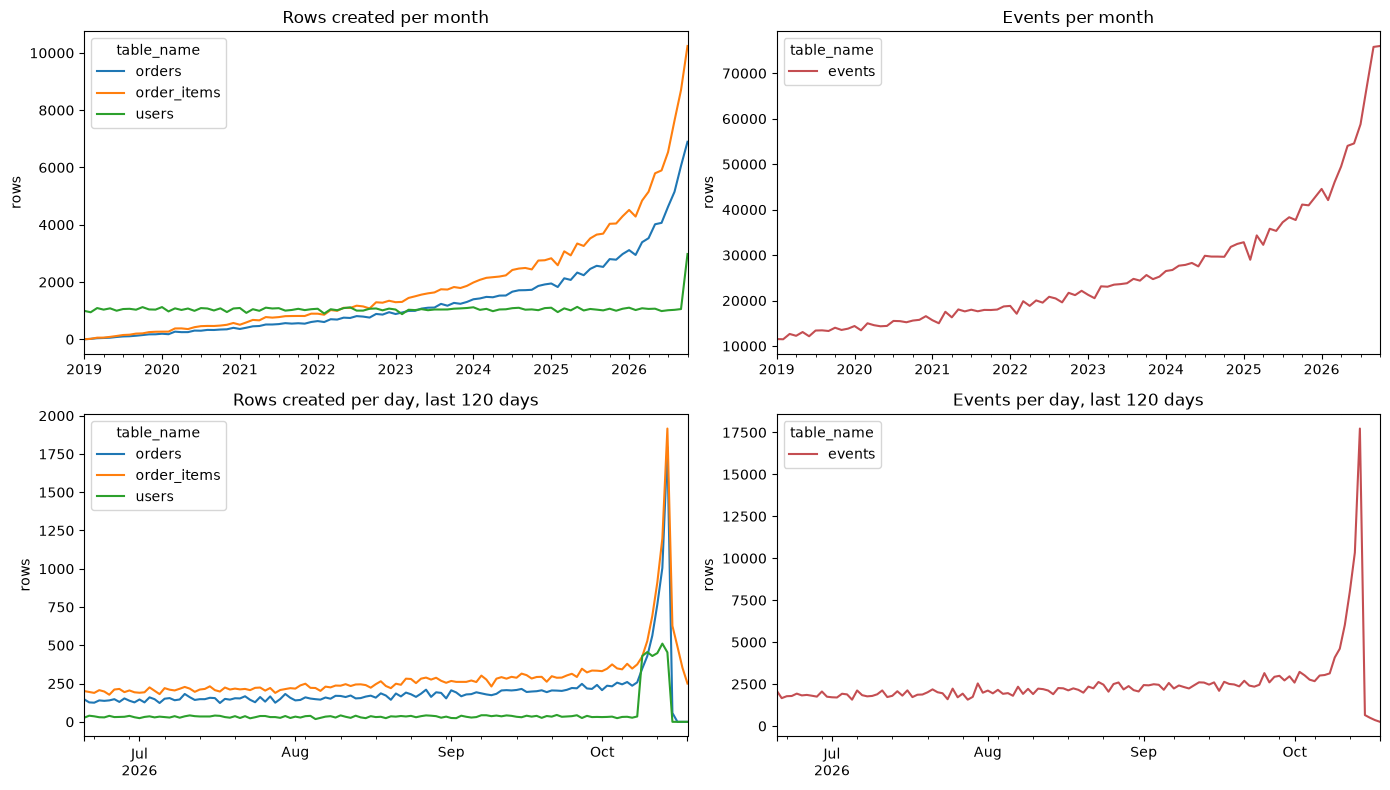

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
monthly[["orders", "order_items", "users"]].plot(ax=axes[0, 0], title="Rows created per month")
monthly[["events"]].plot(ax=axes[0, 1], title="Events per month", color="#C44E52")
recent[["orders", "order_items", "users"]].plot(ax=axes[1, 0], title="Rows created per day, last 120 days")
recent[["events"]].plot(ax=axes[1, 1], title="Events per day, last 120 days", color="#C44E52")
for ax in axes.ravel():
    ax.set_xlabel("")
    ax.set_ylabel("rows")
plt.tight_layout()
plt.show()

In [56]:
# What each candidate start date would give: batch 0 holds everything created before it.
last_event_day = pd.Timestamp(q("""
    SELECT greatest(max(created_at), max(shipped_at), max(delivered_at), max(returned_at)) AS d FROM orders
""").iloc[0, 0]).tz_convert("UTC").normalize()
last_order_day = pd.Timestamp(q("SELECT max(created_at) AS d FROM orders").iloc[0, 0]).tz_convert("UTC").normalize()

candidates = []
for start in ["2025-01-01", "2026-01-01", "2026-04-01", "2026-07-01"]:
    s = pd.Timestamp(start, tz="UTC")
    r = q(f"""
        SELECT count(*) FILTER (WHERE created_at <  TIMESTAMPTZ '{start}') AS orders_in_batch_0,
               count(*) FILTER (WHERE created_at >= TIMESTAMPTZ '{start}') AS orders_replayed
        FROM orders
    """).iloc[0]
    days_to_last_order = (last_order_day - s).days
    candidates.append({
        "start_date": start,
        "orders_in_batch_0": int(r["orders_in_batch_0"]),
        "orders_replayed": int(r["orders_replayed"]),
        "days_to_last_order": days_to_last_order,
        "days_to_last_lifecycle_event": (last_event_day - s).days,
        "avg_orders_per_replayed_day": round(r["orders_replayed"] / max(days_to_last_order, 1), 1),
    })
pd.DataFrame(candidates)


,start_date,orders_in_batch_0,orders_replayed,days_to_last_order,days_to_last_lifecycle_event,avg_orders_per_replayed_day
0,2025-01-01,52554,72450,652,661,111.1
1,2026-01-01,81210,43794,287,296,152.6
2,2026-04-01,90659,34345,197,206,174.3
3,2026-07-01,102273,22731,106,115,214.4



### Live source against the snapshot
Recorded on 2026-10-20: the live `orders` table had **125,386** rows and was last modified **2026-10-20 03:12 UTC**, against 125,004 rows and 2026-10-15 04:02 UTC in the snapshot. The daily rewrite does not happen at a fixed time, and row counts move in both directions, which is why the project works from a frozen snapshot. Set `CHECK_LIVE_SOURCE = True` in section 1 to repeat the comparison (needs GCP credentials).

In [59]:
if CHECK_LIVE_SOURCE:
    from google.cloud import bigquery

    bq = bigquery.Client(project=os.getenv("GCP_PROJECT"))
    dataset = os.getenv("BQ_DATASET_ID")  # for example bigquery-public-data.thelook_ecommerce
    live_rows = []
    for name in manifest["table_name"]:
        t = bq.get_table(f"{dataset}.{name}")
        live_rows.append({"table_name": name, "live_rows": t.num_rows, "live_modified_utc": t.modified})
    live = pd.DataFrame(live_rows).merge(manifest, on="table_name")
    live["row_difference"] = live["live_rows"] - live["row_count"]
    display(live)
else:
    print("Skipped: set CHECK_LIVE_SOURCE = True in section 1 to compare the live tables with the snapshot.")


,table_name,live_rows,live_modified_utc,row_count,source_modified_at_utc,snapshot_taken_at_utc,row_difference
0,distribution_centers,10,2026-10-22 03:31:10.226000+00:00,10,2026-10-15 04:02:20.620,2026-10-15 14:23:20.689588,0
1,events,2426072,2026-10-22 03:30:54.584000+00:00,2421494,2026-10-15 04:01:59.415,2026-10-15 14:23:20.689588,4578
2,inventory_items,490461,2026-10-22 03:30:52.894000+00:00,488459,2026-10-15 04:01:55.340,2026-10-15 14:23:20.689588,2002
3,order_items,181596,2026-10-22 03:30:53.281000+00:00,181081,2026-10-15 04:01:49.575,2026-10-15 14:23:20.689588,515
4,orders,125090,2026-10-22 03:30:46.719000+00:00,125004,2026-10-15 04:01:54.719,2026-10-15 14:23:20.689588,86
5,products,29120,2026-10-22 03:30:47.916000+00:00,29120,2026-10-15 04:01:47.555,2026-10-15 14:23:20.689588,0
6,users,100000,2026-10-22 03:31:03.884000+00:00,100000,2026-10-15 04:02:11.990,2026-10-15 14:23:20.689588,0


In [ ]:
con.close()